In [47]:
import numpy as np
import matplotlib.pyplot as plt

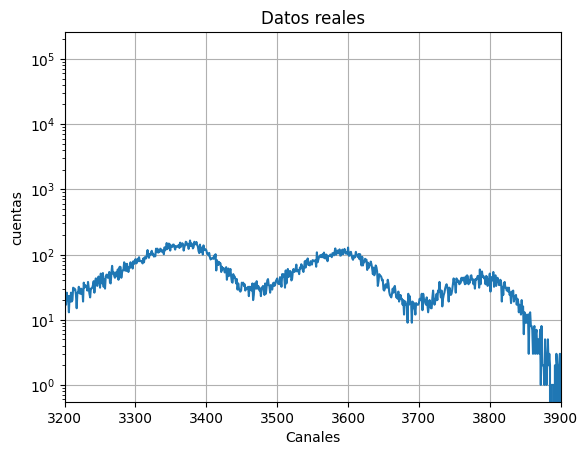

In [48]:
data = np.loadtxt("Datos reales\MCA_data.dat")  #Datos reales  

plt.semilogy(data[:,0])
plt.title("Datos reales")
plt.xlabel("Canales")
plt.ylabel("cuentas")
plt.xlim(3200, 3900)
plt.grid(True)
plt.show()


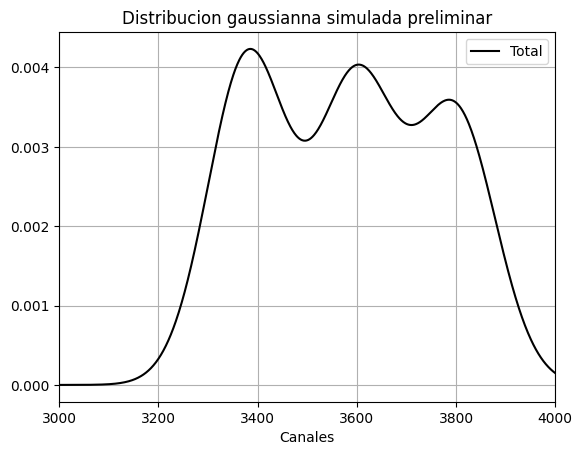

In [49]:
from SimulacionDatos import Canales, Total_dist, gaussian

plt.plot(Canales, Total_dist, label='Total', color='black')
plt.xlabel("Canales")
plt.title("Distribucion gaussianna simulada preliminar")
plt.legend()
plt.grid(True)
plt.xlim(3000, 4000)
plt.show()

In [50]:
from Ruido import Desplazamiento, noise
Temperaturas = np.random.randint(0, 500, size=100) 
Datos = np.zeros((Temperaturas.size, Canales.size))   
Datos_ruidosos = np.zeros((Temperaturas.size, Canales.size))
for i in range(Temperaturas.size):
    DT = Desplazamiento(Temperaturas[i])
    Datos[i] = gaussian(Canales , mu=3380 + DT) * 0.83 + gaussian(Canales , mu=3600 + DT) * 0.76 + gaussian(Canales , mu=3800 + DT) * 0.68
    Datos_ruidosos[i] = noise(Datos[i], 400)



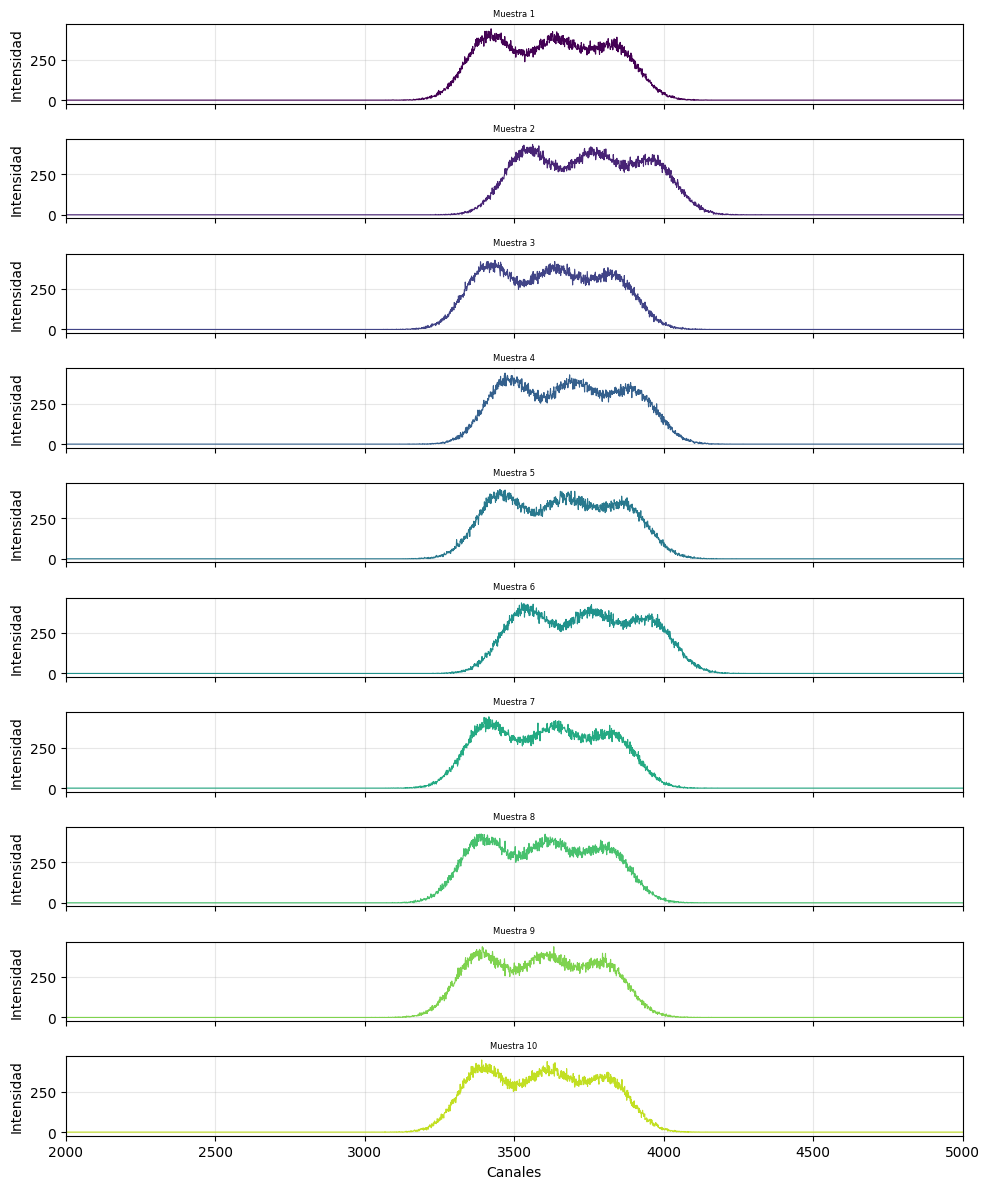

In [51]:
n = Datos_ruidosos.shape[0]
fig, axes = plt.subplots(10, 1, figsize=(10, 12), sharex=True, sharey=True)
axes = axes.ravel()
colors = plt.cm.viridis(np.linspace(0, 10, n))

for i, ax in enumerate(axes):
    if i < n:
        ax.plot(Canales, Datos_ruidosos[i], color=colors[i], lw=0.8)
        ax.set_title(f"Muestra {i+1}", fontsize=6)
        ax.grid(True, alpha=0.3)
    else:
        ax.axis('off')

for ax in axes[:n]:
    ax.set_ylabel("Intensidad")

axes[-1].set_xlabel("Canales")
plt.xlim(2000, 5000)
plt.tight_layout()
plt.show()

In [62]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

Datossim = np.loadtxt(Path("Datos sinteticos") / "Datos_simulados_0.dat")
plt.plot(Datossim[:, 0], Datossim[:, 1])
plt.xlabel("Canal")
plt.ylabel("Intensidad")
plt.title("Espectro 0 simulado")
plt.xlim(2000, 5000)
plt.show()

ValueError: could not convert string 'Canales' to float64 at row 0, column 1.